# Bloc 1 — Modèles du diagnostic des sols (Kizuna Regenerate)

Ce notebook présente et teste les deux modèles du bloc 1 :

1. **Modèle IA « Cd à partir d'un relevé XRF »** — un XRF portable mesure bien Cu, Zn, Pb, Fe… mais mal le cadmium.
   On entraîne un classifieur qui estime la probabilité que **Cd ≥ 1 mg/kg** (seuil ORANGE) à partir des éléments XRF,
   du pH, de la texture et de l'occupation du sol, pour **décider quels échantillons envoyer au labo**.
   Données : **LUCAS Heavy Metals 2009** (ESDAC / JRC, 21 684 sols européens, sans coordonnées).
2. **Interpolation IDW + plan des capteurs** — combien de points de relevé faut-il selon la taille de la parcelle ?
   On le mesure sur des parcelles **synthétiques réalistes** (générateur `diagnostics.synthetic`).

Le code de production est dans `diagnostics/` (`ml_cd.py`, `idw.py`, `sampling.py`, `synthetic.py`) ; ce notebook
l'importe pour que les résultats soient exactement ceux de l'application.

> **Limites honnêtes** : sols européens (peu de sols très pollués : 5,6 % au-dessus de 1 mg/kg), pas de coordonnées,
> contexte différent de Gabès. Le modèle sert à *trier* les échantillons, pas à remplacer le labo.
> Il faudra le recaler avec des mesures réelles de Gabès.

In [1]:
# Configuration : chemin du fichier ESDAC (variable d'environnement LUCAS_HM_XLSX sinon valeur par défaut)
import os, sys, json, math
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.environ.setdefault("DJANGO_SETTINGS_MODULE", "config.settings")
import django; django.setup()

HEAVY_METALS_XLSX = Path(os.environ.get("LUCAS_HM_XLSX", Path.home() / "Downloads" / "HeavyMetals.xlsx"))
print("Données :", HEAVY_METALS_XLSX, "| trouvé :", HEAVY_METALS_XLSX.exists())

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
ROUGE, ORANGE, VERT, OLIVE, EAU, SOLEIL = "#B83227", "#B85C0E", "#23774A", "#4A5A2A", "#1F6FA8", "#E8A916"

Données : C:\Users\LENOVO\Downloads\HeavyMetals.xlsx | trouvé : True


## 1. Données LUCAS Heavy Metals 2009

In [2]:
from diagnostics.ml_cd import charger_lucas, NUM, CAT, MEDITERRANEE, SEUIL_CD

df = charger_lucas(HEAVY_METALS_XLSX)
y = (df["cd"] >= SEUIL_CD).astype(int)
print(f"{len(df):,} échantillons · {df['pays'].nunique()} pays")
print(f"Cd sous la limite de détection : {(df['cd'] == 0).mean():.0%}")
print(f"Cd >= 1 mg/kg (cible) : {y.sum():,} ({y.mean():.1%}) · Cd >= 3 mg/kg : {(df['cd'] >= 3).sum()}")
df[NUM].describe().T.round(1)

21,684 échantillons · 28 pays
Cd sous la limite de détection : 73%
Cd >= 1 mg/kg (cible) : 1,203 (5.5%) · Cd >= 3 mg/kg : 50


,count,mean,std,min,25%,50%,75%,max
Pb_mg_kg,21684.0,18.3,20.1,0.0,9.0,14.1,21.0,454.1
Zn_mg_kg,21684.0,46.2,40.3,0.0,22.7,39.8,60.6,1941.3
Cu_mg_kg,21684.0,16.9,21.9,0.0,6.1,11.6,20.4,496.3
Ni_mg_kg,21684.0,30.5,144.2,0.0,6.4,14.6,28.6,5742.6
Cr_mg_kg,21684.0,35.9,225.4,0.0,10.0,19.4,33.6,8912.1
Mn_mg_kg,21684.0,504.9,720.5,0.8,174.8,373.0,631.6,21892.2
Fe_mg_kg,21684.0,18620.5,16036.0,22.2,8631.2,15809.9,24983.0,422411.4
Co_mg_kg,21684.0,8.2,7.6,0.0,3.4,6.7,11.0,171.7
pH,21682.0,6.3,1.3,3.2,5.2,6.2,7.8,10.2
OC,21441.0,51.9,85.3,25.0,25.0,25.0,25.0,575.0


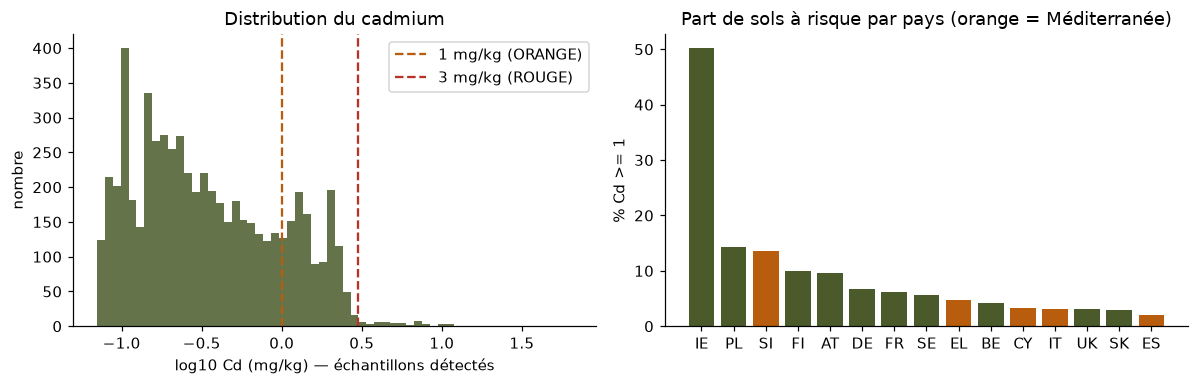

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
cd = df.loc[df.cd > 0, "cd"]
ax[0].hist(np.log10(cd), bins=60, color=OLIVE, alpha=.85)
for s, c, l in [(1, ORANGE, "1 mg/kg (ORANGE)"), (3, ROUGE, "3 mg/kg (ROUGE)")]:
    ax[0].axvline(np.log10(s), color=c, ls="--", label=l)
ax[0].set(xlabel="log10 Cd (mg/kg) — échantillons détectés", ylabel="nombre", title="Distribution du cadmium")
ax[0].legend()
taux = df.assign(y=y).groupby("pays")["y"].mean().sort_values(ascending=False).head(15) * 100
ax[1].bar(taux.index, taux.values, color=[ORANGE if p in MEDITERRANEE else OLIVE for p in taux.index])
ax[1].set(ylabel="% Cd >= 1", title="Part de sols à risque par pays (orange = Méditerranée)")
plt.tight_layout(); plt.show()

## 2. Entraînement — découpage aléatoire 80 / 20

Modèle : `HistGradientBoostingClassifier` (gère les valeurs manquantes et les catégories, poids équilibrés car la
classe positive est rare). Variables : éléments mesurables par XRF (`Pb, Zn, Cu, Ni, Cr, Mn, Fe, Co`), classe de pH,
classe de carbone organique, texture USDA, occupation du sol.

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve, precision_recall_curve, average_precision_score
from diagnostics.ml_cd import _modele, _evaluer

X = df[NUM + CAT]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=0)
modele = _modele().fit(Xtr, ytr)
p = modele.predict_proba(Xte)[:, 1]
res = _evaluer(yte, p)
print(json.dumps(res, indent=1, ensure_ascii=False))

{
 "n": 4337,
 "positifs": 241,
 "taux_positifs_pct": 5.6,
 "auc": 0.84,
 "precision_moyenne": 0.384,
 "tri_labo": {
  "rappel_vise_pct": 90,
  "seuil_probabilite": 0.195,
  "echantillons_envoyes_au_labo_pct": 49.6,
  "analyses_economisees_pct": 50.4,
  "precision_des_envoyes_pct": 10.1
 }
}


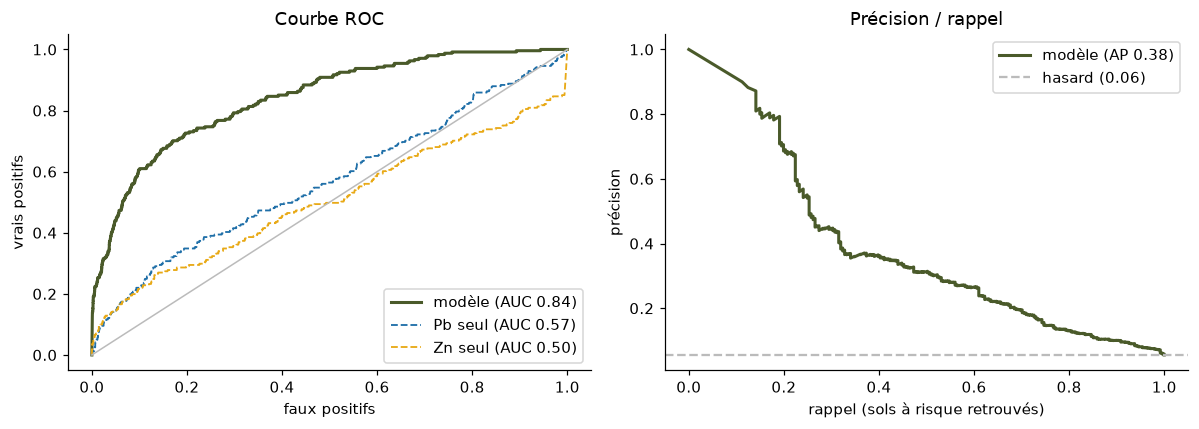

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
fpr, tpr, _ = roc_curve(yte, p)
ax[0].plot(fpr, tpr, color=OLIVE, lw=2, label=f"modèle (AUC {roc_auc_score(yte, p):.2f})")
for col, c in [("Pb_mg_kg", EAU), ("Zn_mg_kg", SOLEIL)]:
    f2, t2, _ = roc_curve(yte, Xte[col].fillna(0))
    ax[0].plot(f2, t2, color=c, lw=1.2, ls="--", label=f"{col.split('_')[0]} seul (AUC {roc_auc_score(yte, Xte[col].fillna(0)):.2f})")
ax[0].plot([0, 1], [0, 1], color="#bbb", lw=1)
ax[0].set(xlabel="faux positifs", ylabel="vrais positifs", title="Courbe ROC"); ax[0].legend()
pr, rc, _ = precision_recall_curve(yte, p)
ax[1].plot(rc, pr, color=OLIVE, lw=2, label=f"modèle (AP {average_precision_score(yte, p):.2f})")
ax[1].axhline(yte.mean(), color="#bbb", ls="--", label=f"hasard ({yte.mean():.2f})")
ax[1].set(xlabel="rappel (sols à risque retrouvés)", ylabel="précision", title="Précision / rappel"); ax[1].legend()
plt.tight_layout(); plt.show()

## 3. Ce qui compte pour le pitch : combien d'analyses labo économisées ?

On classe les échantillons par probabilité et on n'envoie au labo que ceux au-dessus d'un seuil.
Pour chaque seuil : **part des échantillons envoyés** vs **part des sols à risque retrouvés** (rappel).

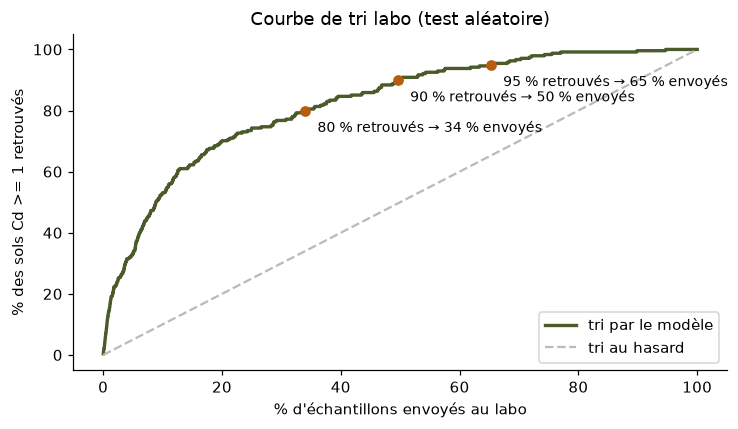

In [6]:
ordre = np.argsort(-p); yt = np.asarray(yte)[ordre]
envoyes = np.arange(1, len(yt) + 1) / len(yt) * 100
rappel = np.cumsum(yt) / yt.sum() * 100
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(envoyes, rappel, color=OLIVE, lw=2.2, label="tri par le modèle")
ax.plot([0, 100], [0, 100], color="#bbb", ls="--", label="tri au hasard")
for r in (80, 90, 95):
    i = np.argmax(rappel >= r)
    ax.scatter(envoyes[i], r, color=ORANGE, zorder=3)
    ax.annotate(f"{r} % retrouvés → {envoyes[i]:.0f} % envoyés", (envoyes[i], r), xytext=(8, -14), textcoords="offset points", fontsize=9)
ax.set(xlabel="% d'échantillons envoyés au labo", ylabel="% des sols Cd >= 1 retrouvés", title="Courbe de tri labo (test aléatoire)")
ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

## 4. Quelles variables utilise le modèle ? (importance par permutation)

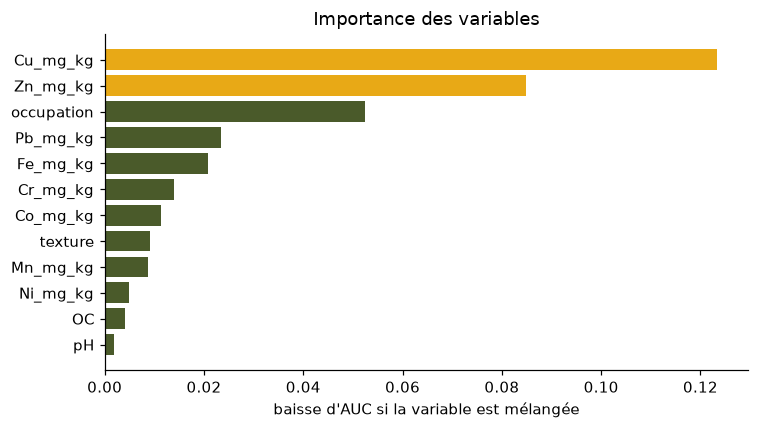

Cu et Zn (mesurés par XRF) portent l'essentiel du signal : le Cd des engrais phosphatés et des industries va souvent avec le zinc et le cuivre.


In [7]:
from sklearn.inspection import permutation_importance
imp = permutation_importance(modele, Xte, yte, scoring="roc_auc", n_repeats=5, random_state=0)
s = pd.Series(imp.importances_mean, index=NUM + CAT).sort_values()
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(s.index, s.values, color=[SOLEIL if i in ("Cu_mg_kg", "Zn_mg_kg") else OLIVE for i in s.index])
ax.set(xlabel="baisse d'AUC si la variable est mélangée", title="Importance des variables")
plt.tight_layout(); plt.show()
print("Cu et Zn (mesurés par XRF) portent l'essentiel du signal : le Cd des engrais phosphatés et des industries va souvent avec le zinc et le cuivre.")

## 5. Test géographique : le modèle tient-il en Méditerranée ?

Entraînement **hors** Méditerranée, test **sur** ES, IT, EL, PT, CY, MT, HR, SI — les sols les plus proches de ceux de la Tunisie.
C'est le chiffre le plus honnête à présenter.

In [8]:
med = df["pays"].isin(MEDITERRANEE)
m_med = _modele().fit(X[~med], y[~med])
res_med = _evaluer(y[med], m_med.predict_proba(X[med])[:, 1])
comparaison = pd.DataFrame({"aléatoire 80/20": {**{k: res[k] for k in ("n", "positifs", "auc", "precision_moyenne")}, **res["tri_labo"]},
                            "test Méditerranée": {**{k: res_med[k] for k in ("n", "positifs", "auc", "precision_moyenne")}, **res_med["tri_labo"]}})
comparaison

,aléatoire 80/20,test Méditerranée
n,4337.000,5219.000
positifs,241.000,144.000
auc,0.840,0.737
precision_moyenne,0.384,0.193
rappel_vise_pct,90.000,90.000
seuil_probabilite,0.195,0.113
echantillons_envoyes_au_labo_pct,49.600,72.200
analyses_economisees_pct,50.400,27.800
precision_des_envoyes_pct,10.100,3.400


## 6. Comparaison avec des modèles plus simples

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
Xn_tr, Xn_te = np.log1p(Xtr[NUM[:-2]].fillna(0)), np.log1p(Xte[NUM[:-2]].fillna(0))
logit = make_pipeline(SimpleImputer(), StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")).fit(Xn_tr, ytr)
pd.Series({
    "Pb seul": roc_auc_score(yte, Xte["Pb_mg_kg"].fillna(0)),
    "Zn seul": roc_auc_score(yte, Xte["Zn_mg_kg"].fillna(0)),
    "Régression logistique (métaux XRF, log)": roc_auc_score(yte, logit.predict_proba(Xn_te)[:, 1]),
    "Gradient boosting (modèle retenu)": roc_auc_score(yte, p),
}, name="AUC").round(3).to_frame()

,AUC
Pb seul,0.570
Zn seul,0.504
"Régression logistique (métaux XRF, log)",0.696
Gradient boosting (modèle retenu),0.840


## 7. Exemple : un relevé XRF dans une parcelle de Gabès

In [10]:
releves = pd.DataFrame([
    {"point": "P1 (près de l'usine)", "Pb_mg_kg": 120, "Zn_mg_kg": 320, "Cu_mg_kg": 95, "pH": 7.9},
    {"point": "P2 (oasis, moyen)",    "Pb_mg_kg": 55,  "Zn_mg_kg": 140, "Cu_mg_kg": 40, "pH": 8.0},
    {"point": "P3 (loin, propre)",    "Pb_mg_kg": 22,  "Zn_mg_kg": 60,  "Cu_mg_kg": 18, "pH": 8.1},
    {"point": "P4 (sol de référence)", "Pb_mg_kg": 15, "Zn_mg_kg": 40,  "Cu_mg_kg": 12, "pH": 8.1},
])
Xex = pd.DataFrame({c: releves.get(c, np.nan) for c in NUM})
for c in CAT:
    Xex[c] = pd.Categorical(["sandy loam" if c == "texture" else "Cropland"] * len(releves), categories=X[c].cat.categories)
seuil = res["tri_labo"]["seuil_probabilite"]
releves["P(Cd >= 1)"] = modele.predict_proba(Xex)[:, 1].round(2)
releves["décision"] = np.where(releves["P(Cd >= 1)"] >= seuil, "envoyer au labo", "XRF suffit")
print(f"Seuil de tri = {seuil:.3f} (choisi pour retrouver 90 % des sols à risque : volontairement prudent).")
releves

Seuil de tri = 0.195 (choisi pour retrouver 90 % des sols à risque : volontairement prudent).


,point,Pb_mg_kg,Zn_mg_kg,Cu_mg_kg,pH,P(Cd >= 1),décision
0,P1 (près de l'usine),120,320,95,7.9,0.91,envoyer au labo
1,"P2 (oasis, moyen)",55,140,40,8.0,0.78,envoyer au labo
2,"P3 (loin, propre)",22,60,18,8.1,0.38,envoyer au labo
3,P4 (sol de référence),15,40,12,8.1,0.27,envoyer au labo


> **À retenir** : même le sol de référence (P4) dépasse le seuil de tri. Sur un sol **calcaire cultivé à pH 8**, comme à Gabès,
> le modèle européen est très prudent : la probabilité de base est élevée pour ce type de sol. En l'état, il **classe bien les points
> entre eux** (P1 > P2 > P3 > P4), mais il n'économiserait presque pas d'analyses sur une parcelle de Gabès.
> Il faut **recaler le seuil** avec quelques dizaines d'analyses labo locales avant de s'en servir pour réduire les coûts.

## 8. Interpolation IDW : combien de points de relevé ?

Le générateur (`diagnostics.synthetic`) crée des parcelles « vérité terrain » :
Cd, CE, Pb selon la distance à la source et le vent (ordres de grandeur publiés pour Gabès), pH et texture tirés des
sols LUCAS méditerranéens calcaires, variabilité spatialement corrélée et points chauds.
On place *n* points (`diagnostics.sampling.disposition`), on simule les erreurs d'appareil, on interpole (IDW) et on
compte les cases qui ont la bonne couleur.

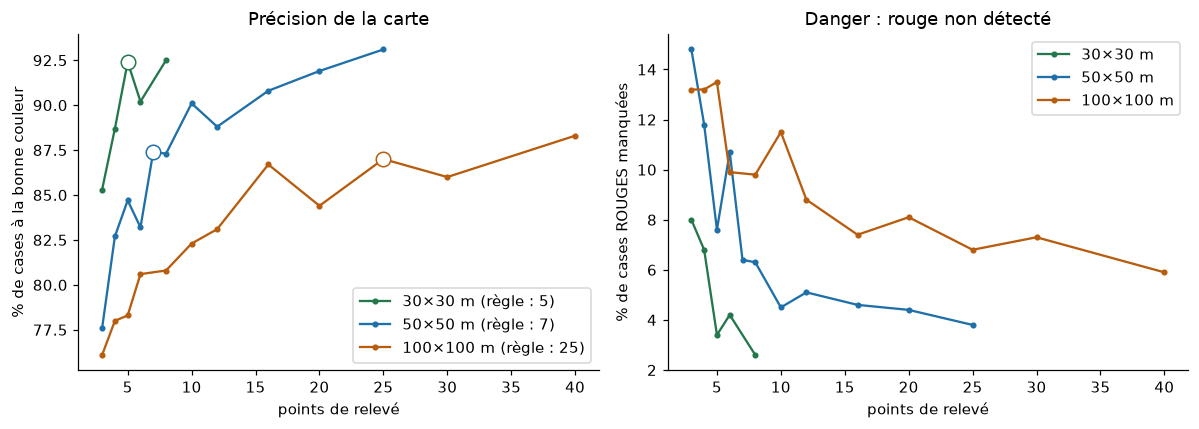

Règle retenue : max(5, surface / 400 m²) points — au-delà, le gain devient faible (rond blanc = règle).


In [11]:
from diagnostics.management.commands.bloc1_experiment import evaluer
from diagnostics.sampling import nb_points_recommande
rng = np.random.default_rng(42)
tailles = [(30, 30), (50, 50), (100, 100)]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for (w, l), c in zip(tailles, [VERT, EAU, ORANGE]):
    reco = nb_points_recommande(w, l)
    ns = sorted({n for n in [3, 4, 5, 6, 8, 10, 12, 16, 20, 25, 30, 40] if n <= (w // 10) * (l // 10)} | {reco})
    r = [evaluer(w, l, n, 150, rng) for n in ns]  # 150 parcelles simulées par point
    ax[0].plot(ns, [x["couleur_correcte_pct"] for x in r], "-o", color=c, ms=3, label=f"{w}×{l} m (règle : {reco})")
    ax[1].plot(ns, [x["rouges_manques_pct"] for x in r], "-o", color=c, ms=3, label=f"{w}×{l} m")
    i = ns.index(reco)
    ax[0].scatter([reco], [r[i]["couleur_correcte_pct"]], s=90, facecolor="white", edgecolor=c, zorder=3)
ax[0].set(xlabel="points de relevé", ylabel="% de cases à la bonne couleur", title="Précision de la carte")
ax[1].set(xlabel="points de relevé", ylabel="% de cases ROUGES manquées", title="Danger : rouge non détecté")
ax[0].legend(); ax[1].legend(); plt.tight_layout(); plt.show()
print("Règle retenue : max(5, surface / 400 m²) points — au-delà, le gain devient faible (rond blanc = règle).")

## 9. Exemple visuel : vérité terrain vs carte interpolée

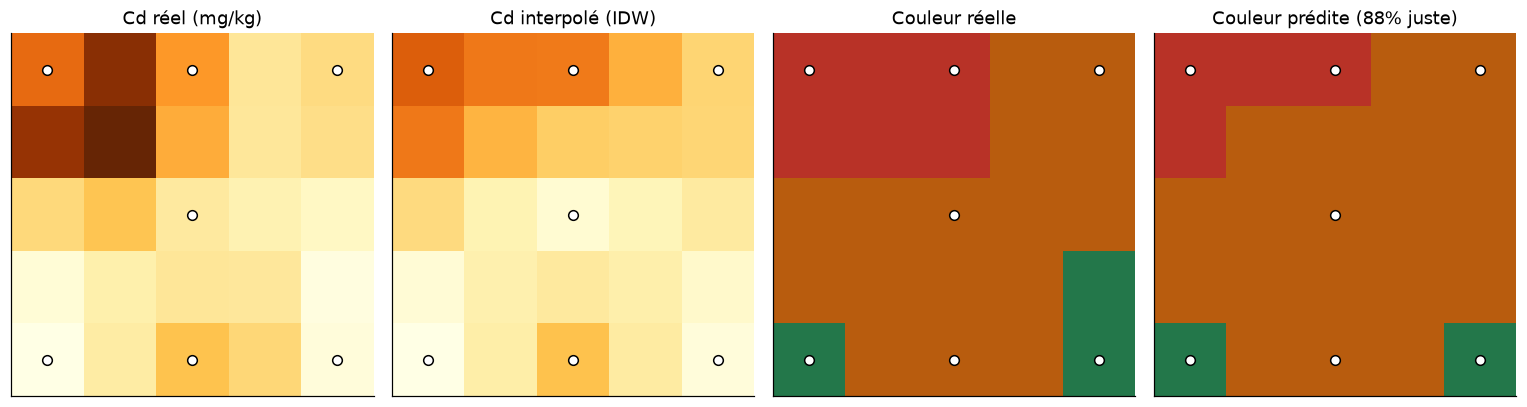

IDW : {'puissance': 3.0, 'nb_points': 7, 'espacement_m': 18.9}
Validation croisée (MAE) : {'CE_dS_m': 1.14, 'pH': 0.15, 'Cd_mg_kg': 1.37, 'Pb_mg_kg': 19.5}


In [12]:
from matplotlib.colors import ListedColormap
from diagnostics.synthetic import generer_parcelle, mesurer
from diagnostics.sampling import disposition
from diagnostics.idw import interpoler_grille
from diagnostics.couleur import couleur_case

nl, nc = 5, 5
verite = generer_parcelle(nl, nc, distance_km=8, cap=135, seed=4, points_chauds=1)  # parcelle à 8 km, sous le vent
pts = disposition(nl, nc, nb_points_recommande(50, 50))
cases, info = interpoler_grille(mesurer(verite, pts, np.random.default_rng(1)), nl, nc)
code = {"ROUGE": 0, "ORANGE": 1, "VERT": 2}
vrai = np.array([[code[couleur_case(verite["CE_dS_m"][i, j], verite["pH"][i, j], verite["Cd_mg_kg"][i, j], verite["Pb_mg_kg"][i, j])] for j in range(nc)] for i in range(nl)])
pred = np.zeros((nl, nc)); conf = np.zeros((nl, nc)); cdp = np.zeros((nl, nc))
for c in cases:
    pred[c["ligne"], c["col"]] = code[couleur_case(c["CE_dS_m"], c["pH"], c["Cd_mg_kg"], c["Pb_mg_kg"])]
    conf[c["ligne"], c["col"]] = c["confiance"]; cdp[c["ligne"], c["col"]] = c["Cd_mg_kg"]
cmap = ListedColormap([ROUGE, ORANGE, VERT])
fig, ax = plt.subplots(1, 4, figsize=(14, 3.6))
ax[0].imshow(verite["Cd_mg_kg"], cmap="YlOrBr"); ax[0].set_title("Cd réel (mg/kg)")
ax[1].imshow(cdp, cmap="YlOrBr", vmin=verite["Cd_mg_kg"].min(), vmax=verite["Cd_mg_kg"].max()); ax[1].set_title("Cd interpolé (IDW)")
ax[2].imshow(vrai, cmap=cmap, vmin=0, vmax=2); ax[2].set_title("Couleur réelle")
ax[3].imshow(pred, cmap=cmap, vmin=0, vmax=2); ax[3].set_title(f"Couleur prédite ({(vrai == pred).mean():.0%} juste)")
for a in ax:
    a.scatter([c for _, c in pts], [l for l, _ in pts], marker="o", s=40, facecolor="white", edgecolor="black")
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()
print("IDW :", {k: v for k, v in info.items() if k != "validation_croisee"})
print("Validation croisée (MAE) :", {k: round(v["mae"], 2) for k, v in info["validation_croisee"].items()})

## 10. Conclusions

| | Résultat |
|---|---|
| **Tri labo du cadmium (test aléatoire)** | AUC ≈ 0,84 — en gardant 90 % des sols à risque, ~50 % d'analyses labo évitées |
| **Test Méditerranée** (le plus réaliste pour la Tunisie) | AUC ≈ 0,74 — ~28 % d'analyses évitées |
| **Variables clés** | cuivre et zinc (mesurés par XRF) ; le plomb seul ne suffit pas |
| **Sur sol calcaire type Gabès** | modèle très prudent : classe bien les points, mais seuil à recaler localement |
| **Plan de capteurs** | max(5, surface / 400 m²) points : 92 % de cases justes sur 30 × 30 m, ~87 % sur 1 ha |

**Prochaines étapes** : recaler le modèle avec des analyses labo de Gabès (même 30 à 50 échantillons),
ajouter la distance à la source quand on aura des coordonnées, et mesurer la variabilité réelle à 10 m pour
ajuster le générateur.

Pour réentraîner le modèle utilisé par l'application : `python manage.py bloc1_train_cd "<chemin>/HeavyMetals.xlsx"`.